# IAU – Fáza 1: Prieskumná analýza dát

## Autori
- Sofiia Berehovykh – 50 %
- Viktoriia Bondarets – 50 %

## 1.1 Základný opis dát

### A. Analýza štruktúry dát

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Jupyter Notebook is working!")
print("Pandas version:", pd.__version__)

Jupyter Notebook is working!
Pandas version: 2.3.3


In [4]:
from pathlib import Path

if Path("data").is_dir():
    DATA_DIR = Path("data")
elif Path("../data").is_dir():
    DATA_DIR = Path("../data")
else:
    raise FileNotFoundError("Data folder not found")

units = pd.read_csv(DATA_DIR / "units.csv", sep=",")
gateways = pd.read_csv(DATA_DIR / "gateways.csv", sep=";")
readings = pd.read_csv(DATA_DIR / "readings.csv", sep="\t")

datasets = {
    "units": units,
    "gateways": gateways,
    "readings": readings
}

for name, df in datasets.items():
    print(f"\nDataset: {name}")
    print(f"Number of records: {df.shape[0]}")
    print(f"Number of attributes: {df.shape[1]}")
    print(f"Attributes: {list(df.columns)}")


Dataset: units
Number of records: 2000
Number of attributes: 9
Attributes: ['year_commission', 'operatorOwner', 'number_serial', 'idDepot', 'codeLine', 'idUnit', 'serviceHours', 'code_model', 'dutyClass']

Dataset: gateways
Number of records: 16000
Number of attributes: 14
Attributes: ['modelHardware', 'Lon', 'macAddress', 'Lat', 'lastSeen', 'signalDbm', 'ipv4', 'dateInstall', 'idDepot', 'Vendor', 'idUnit', 'id_gateway', 'versionFirmware', 'Technician']

Dataset: readings
Number of records: 15041
Number of attributes: 11
Attributes: ['idUnit', 'tsCycle', 'currentMotor', 'dp_filter', 'temperatureOil', 'pressure_reservoir', 'pressure_oil', 'rms_vibration', 'Flowmeter', 'discharge_dewpoint', 'failure']


Dátová sada pozostáva z troch CSV súborov: `units.csv`, `gateways.csv` a `readings.csv`.

Súbor `units.csv` obsahuje 2 000 záznamov a 9 atribútov, `gateways.csv` obsahuje 16 000 záznamov a 14 atribútov a `readings.csv` obsahuje 15 041 záznamov a 11 atribútov.

In [5]:
for name, df in datasets.items():
    print(f"\n{name.upper()}")

    df.info()

    display(df.head())


UNITS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   year_commission  2000 non-null   int64  
 1   operatorOwner    2000 non-null   object 
 2   number_serial    2000 non-null   object 
 3   idDepot          2000 non-null   int64  
 4   codeLine         2000 non-null   object 
 5   idUnit           2000 non-null   int64  
 6   serviceHours     1900 non-null   float64
 7   code_model       2000 non-null   object 
 8   dutyClass        2000 non-null   object 
dtypes: float64(1), int64(3), object(5)
memory usage: 140.8+ KB


,year_commission,operatorOwner,number_serial,idDepot,codeLine,idUnit,serviceHours,code_model,dutyClass
0,2023,Rodrigues,DN-3078-09712,79,L6,1,4341.3,APU-20,L
1,2023,Klapp,XL-3043-34738,93,L5,2,5285.7,XC-7,heavy
2,2021,Kensy GmbH & Co. KGaA,GW-1240-18467,106,L4,3,10698.0,APU-20,H
3,2019,Silva,TE-2427-56403,6,L6,4,18617.3,APU-12,light
4,2020,Chapman-Franklin,AJ-1790-15374,17,L5,5,16261.2,XC-7,1



GATEWAYS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   modelHardware    16000 non-null  object 
 1   Lon              16000 non-null  float64
 2   macAddress       16000 non-null  object 
 3   Lat              16000 non-null  float64
 4   lastSeen         16000 non-null  object 
 5   signalDbm        16000 non-null  float64
 6   ipv4             16000 non-null  object 
 7   dateInstall      16000 non-null  object 
 8   idDepot          16000 non-null  int64  
 9   Vendor           16000 non-null  object 
 10  idUnit           2000 non-null   float64
 11  id_gateway       16000 non-null  object 
 12  versionFirmware  16000 non-null  object 
 13  Technician       16000 non-null  object 
dtypes: float64(4), int64(1), object(9)
memory usage: 1.7+ MB


,modelHardware,Lon,macAddress,Lat,lastSeen,signalDbm,ipv4,dateInstall,idDepot,Vendor,idUnit,id_gateway,versionFirmware,Technician
0,GWX-100,-8.78771,e9:57:6f:a6:6c:4d,39.43900,2024-03-06,-69.3,28.245.203.250,25 Jun 2022,27,Neves Cruz e Filhos,678.0,GW-00000,v3.4.1,Laura Miller
1,NODE-7,-8.75647,d6:23:2d:fb:d4:9a,38.67629,2024/04/26,-60.9,98.152.214.93,05 Jul 2023,119,Schlosser,1970.0,GW-00001,v1.2.5,Dr. Jane Etzold B.Eng.
2,GWX-100,-6.28849,25:f9:96:03:a9:64,39.22058,2024/10/20,-91.6,76.171.110.56,"03/31/2019, 00:00:00",43,Hecker Heser KG,1563.0,GW-00002,v3.4.1,Guenter Aumann MBA.
3,GWX-200,-9.05006,ab:3a:95:be:89:4b,38.80624,"05/24/2024, 00:00:00",-44.0,46.237.250.153,2021/08/23,82,Rohleder,98.0,GW-00003,v3.4.1,Roger Walter
4,NODE-9,-8.03560,a7:1a:59:a9:47:a1,40.34191,2024/04/26,-67.8,107.101.87.190,"05/10/2020, 00:00:00",82,Losekann AG & Co. KG,53.0,GW-00004,v1.2.5,Frau Amalia Holsten



READINGS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15041 entries, 0 to 15040
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   idUnit              15041 non-null  object 
 1   tsCycle             15041 non-null  object 
 2   currentMotor        15041 non-null  float64
 3   dp_filter           14453 non-null  float64
 4   temperatureOil      15041 non-null  float64
 5   pressure_reservoir  15041 non-null  float64
 6   pressure_oil        15041 non-null  float64
 7   rms_vibration       14457 non-null  float64
 8   Flowmeter           15041 non-null  float64
 9   discharge_dewpoint  15041 non-null  float64
 10  failure             15041 non-null  int64  
dtypes: float64(8), int64(1), object(2)
memory usage: 1.3+ MB


,idUnit,tsCycle,currentMotor,dp_filter,temperatureOil,pressure_reservoir,pressure_oil,rms_vibration,Flowmeter,discharge_dewpoint,failure
0,U00861,2023-01-24,4.52714,13.27287,38.37190,8.71234,3.20650,2.98947,26.46027,9.88857,0
1,U00339,2023-03-23,4.29990,30.68875,62.89222,8.30207,3.50414,5.42665,30.37617,3.50537,0
2,U01862,2023/01/02,2.67461,20.64984,44.05538,8.53038,3.31134,3.19845,15.69089,0.94667,0
3,U00659,2023/11/27,4.06722,30.65835,76.27459,8.98351,3.88235,2.13170,24.62591,12.19307,1
4,U00964,"12/30/2023, 22:08:00",7.30514,23.53441,57.95202,8.31182,3.18153,2.50357,21.52352,11.89736,0


Súbory obsahujú numerické aj textové atribúty. Na základe spoločných identifikátorov `idUnit` a `idDepot` je možné identifikovať potenciálne vzťahy medzi súbormi.

In [4]:
for name1, df1 in datasets.items():
    for name2, df2 in datasets.items():
        if name1 < name2:
            common = set(df1.columns) & set(df2.columns)

            print(f"{name1} - {name2}: {sorted(common)}")

gateways - units: ['idDepot', 'idUnit']
gateways - readings: ['idUnit']
readings - units: ['idUnit']


In [5]:
print("\nUnique units:", units["idUnit"].nunique())
print("Unique gateways:", gateways["id_gateway"].nunique())
print("Unique units in readings:", readings["idUnit"].nunique())

print("\nID formats:")
print("Units:", units["idUnit"].head().tolist())
print("Readings:", readings["idUnit"].head().tolist())


Unique units: 2000
Unique gateways: 16000
Unique units in readings: 2118

ID formats:
Units: [1, 2, 3, 4, 5]
Readings: ['U00861', 'U00339', 'U01862', 'U00659', 'U00964']


Pri analýze sme zistili, že identifikátor `idUnit` má v jednotlivých súboroch rozdielny formát. Pred prípadným spojením dát bude potrebné tieto formáty zjednotiť.

### B. Analýza jednotlivých atribútov

In [19]:
sensor_attributes = [
    "currentMotor",
    "dp_filter",
    "temperatureOil",
    "pressure_reservoir",
    "pressure_oil",
    "rms_vibration",
    "Flowmeter",
    "discharge_dewpoint"
]

unit_attributes = ["serviceHours", "year_commission"]
gateway_attributes = ["signalDbm"]

display(readings[sensor_attributes].describe().T)
display(units[unit_attributes].describe().T)
display(gateways[gateway_attributes].describe().T)

,count,mean,std,min,25%,50%,75%,max
currentMotor,15041.0,5.331863,3.804102,0.33561,3.73538,5.11516,6.66536,99.00000
dp_filter,14453.0,24.061256,11.230034,6.64914,16.30112,21.36474,28.82587,113.55145
temperatureOil,15041.0,51.261045,63.587176,-999.00000,46.66289,55.02031,63.19260,95.00000
pressure_reservoir,15041.0,8.699170,0.603690,6.50000,8.28859,8.69973,9.10770,10.50000
pressure_oil,15041.0,3.696864,0.570759,1.50000,3.30548,3.70568,4.08000,6.00000
rms_vibration,14457.0,3.083548,1.642695,0.50000,1.94938,2.71687,3.82950,14.00000
Flowmeter,15041.0,28.046335,3.958383,15.00000,25.37836,28.01675,30.72760,40.00000
discharge_dewpoint,15041.0,8.034140,3.481981,-4.88825,5.67403,8.04172,10.36730,22.33572


,count,mean,std,min,25%,50%,75%,max
serviceHours,1900.0,14184.337316,8557.856017,1192.1,8074.925,12093.85,17868.675,45000.0
year_commission,2000.0,2020.425000,2.454463,2012.0,2019.000,2021.00,2022.000,2024.0


,count,mean,std,min,25%,50%,75%,max
signalDbm,16000.0,-70.052731,9.962019,-109.6,-76.8,-70.0,-63.3,-40.0


Vybrali sme 11 numerických atribútov z troch dátových súborov a pomocou metódy describe() sme vypočítali základné deskriptívne štatistiky, ako sú počet hodnôt, priemer, štandardná odchýlka, minimum, maximum a kvartily. Tieto štatistiky nám pomáhajú lepšie pochopiť rozdelenie hodnôt a identifikovať potenciálne odľahlé hodnoty.

In [20]:
for name, df in datasets.items():
    print(f"\nMissing values in {name}:")

    missing = pd.DataFrame({
        "Count": df.isnull().sum(),
        "Percentage": df.isnull().mean() * 100
    })

    display(missing[missing["Count"] > 0])


Missing values in units:


,Count,Percentage
serviceHours,100,5.0



Missing values in gateways:


,Count,Percentage
idUnit,14000,87.5



Missing values in readings:


,Count,Percentage
dp_filter,588,3.909315
rms_vibration,584,3.882721


Pre každý dátový súbor sme pomocou metódy isnull() zistili počet a percentuálny podiel chýbajúcich hodnôt v jednotlivých atribútoch. Zobrazili sme iba atribúty, ktoré obsahujú aspoň jednu chýbajúcu hodnotu.

Distributions: readings


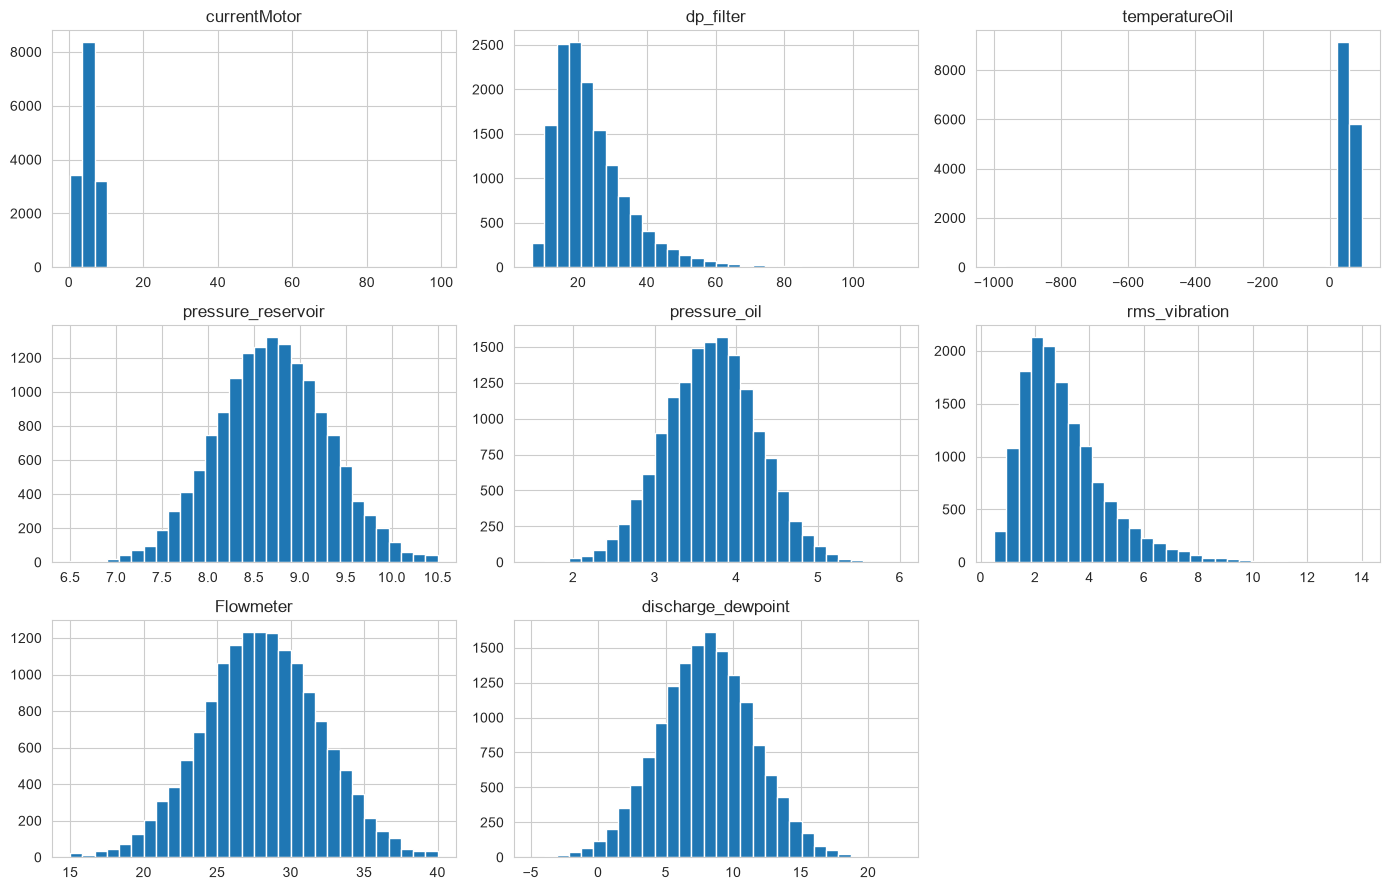

Distributions: units


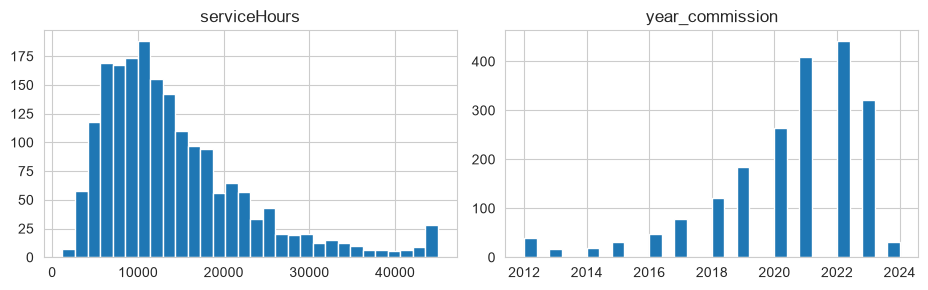

Distributions: gateways


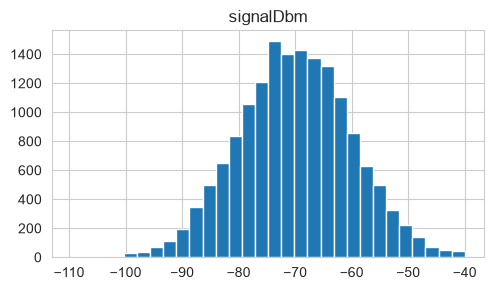

In [21]:
selected_data = [
    ("readings", readings, sensor_attributes),
    ("units", units, unit_attributes),
    ("gateways", gateways, gateway_attributes)
]

for name, df, columns in selected_data:
    print(f"Distributions: {name}")

    df[columns].hist(
        bins=30,
        figsize=(14, 3 * ((len(columns) + 2) // 3)),
        layout=((len(columns) + 2) // 3, 3)
    )

    plt.tight_layout()
    plt.show()

Pre 11 vybraných numerických atribútov sme vytvorili histogramy, ktoré zobrazujú rozdelenie ich hodnôt. Pomocou nich môžeme identifikovať tvar rozdelenia, najčastejšie hodnoty a možné odľahlé pozorovania.

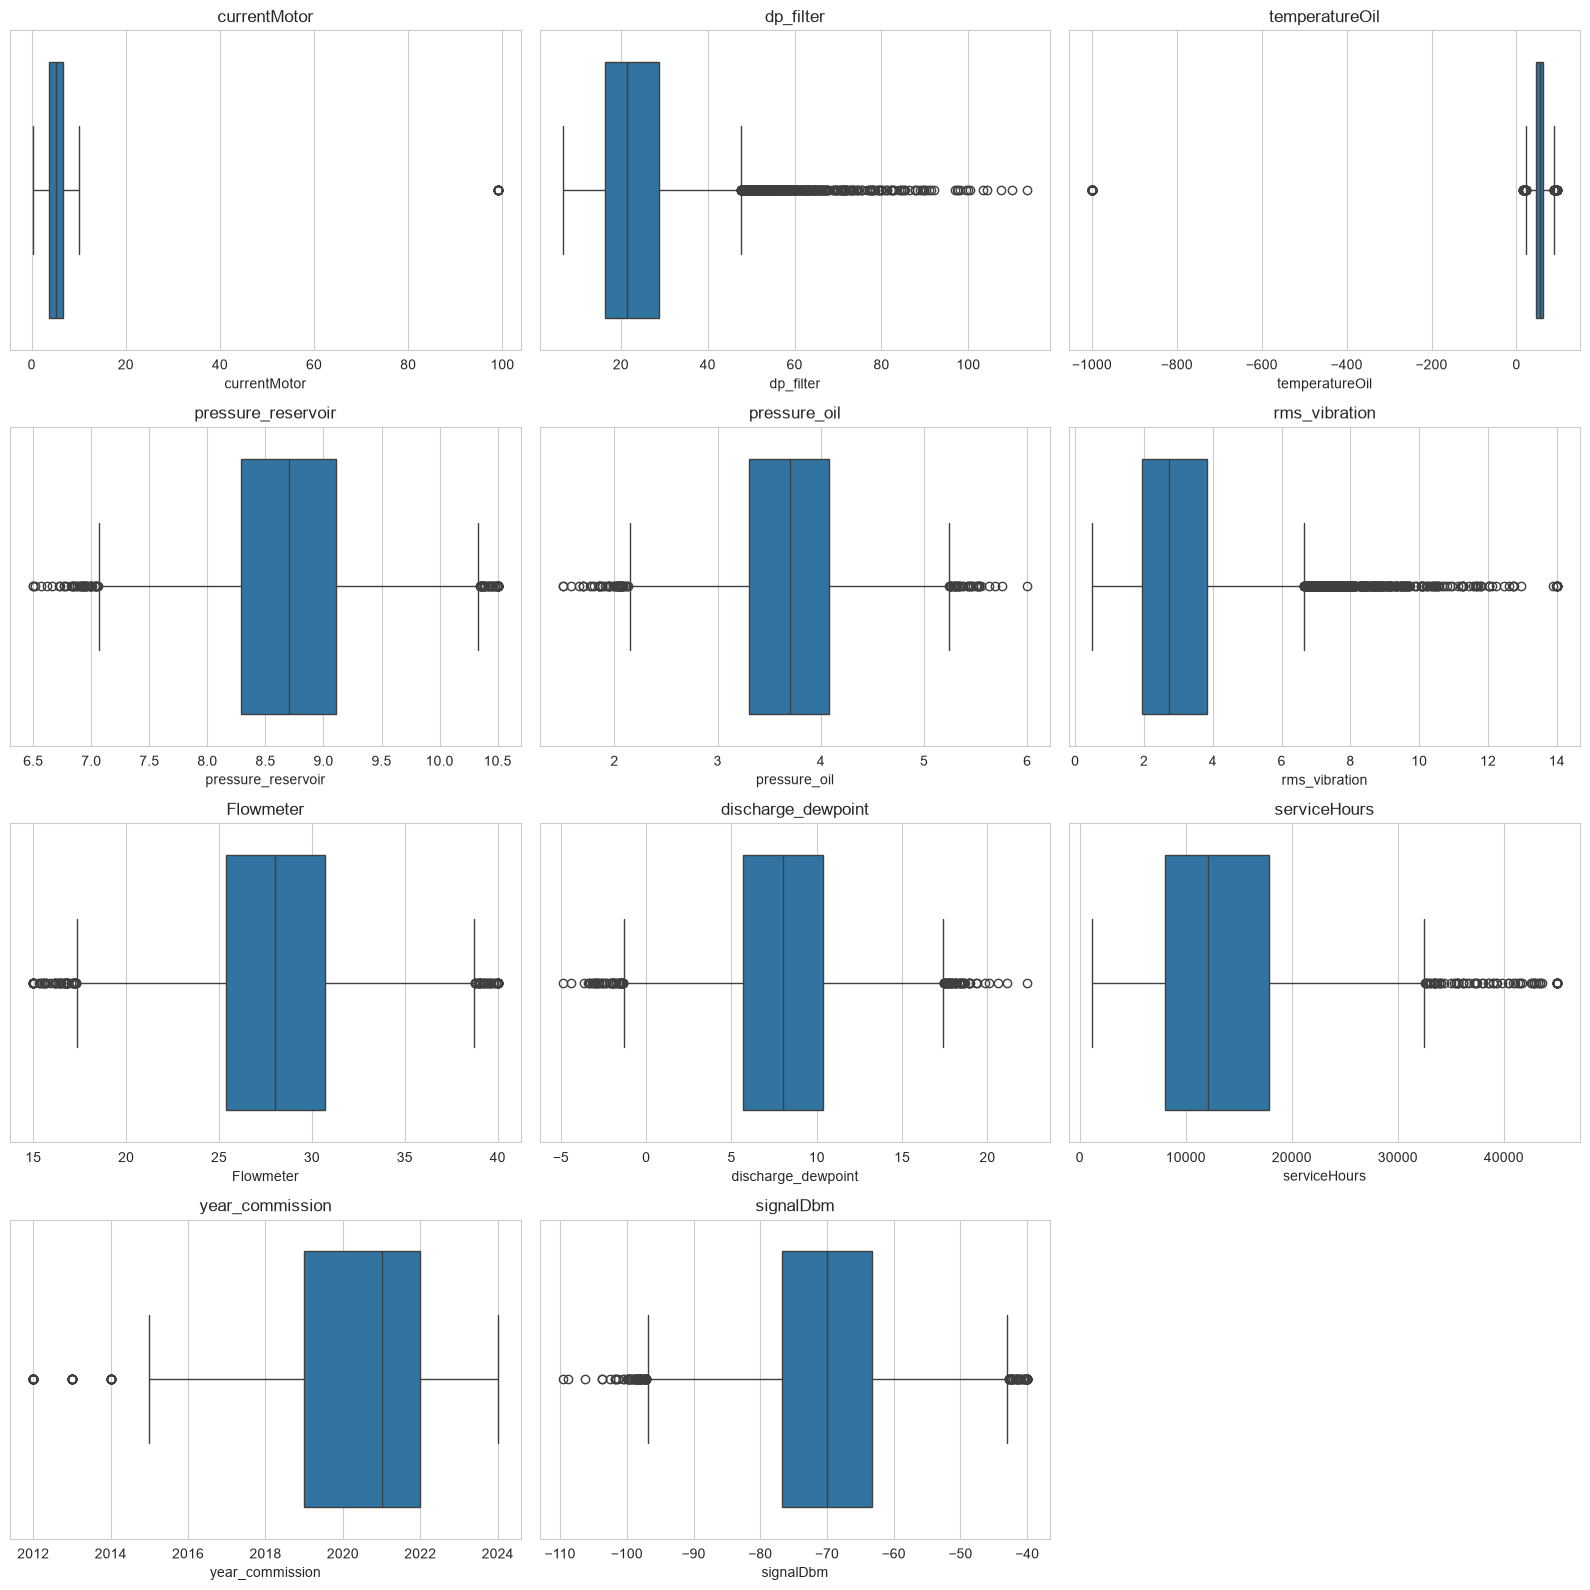

In [23]:
fig, axes = plt.subplots(4, 3, figsize=(16, 16))

for ax, (name, df, columns) in zip(
    axes.flatten(),
    [(name, df, col) for name, df, cols in selected_data for col in cols]
):
    sns.boxplot(
        x=df[columns],
        ax=ax
    )

    ax.set_title(columns)

axes.flatten()[-1].set_visible(False)

plt.tight_layout()
plt.show()

Pre 11 senzorových atribútov sme vytvorili boxploty, ktoré zobrazujú medián, kvartily, rozptyl hodnôt a potenciálne odľahlé hodnoty. Pomocou nich môžeme identifikovať extrémne hodnoty a porovnať rozdelenia jednotlivých atribútov.

In [10]:
range_check = pd.DataFrame({
    "Min": readings[sensor_attributes].min(),
    "Max": readings[sensor_attributes].max(),
    "Negative values": (
        readings[sensor_attributes] < 0
    ).sum(),
    "Missing values": readings[sensor_attributes].isna().sum()
})

display(range_check)

,Min,Max,Negative values,Missing values
currentMotor,0.33561,99.00000,0,0
dp_filter,6.64914,113.55145,0,588
temperatureOil,-999.00000,95.00000,53,0
pressure_reservoir,6.50000,10.50000,0,0
pressure_oil,1.50000,6.00000,0,0
rms_vibration,0.50000,14.00000,0,584
Flowmeter,15.00000,40.00000,0,0
discharge_dewpoint,-4.88825,22.33572,160,0


Pre senzorové atribúty sme zistili minimálne a maximálne hodnoty, počet záporných a chýbajúcich hodnôt. Cieľom je identifikovať potenciálne nesprávne alebo neobvyklé hodnoty v dátach.

failure
0    13227
1     1814
Name: count, dtype: int64
failure
0    87.939632
1    12.060368
Name: proportion, dtype: float64


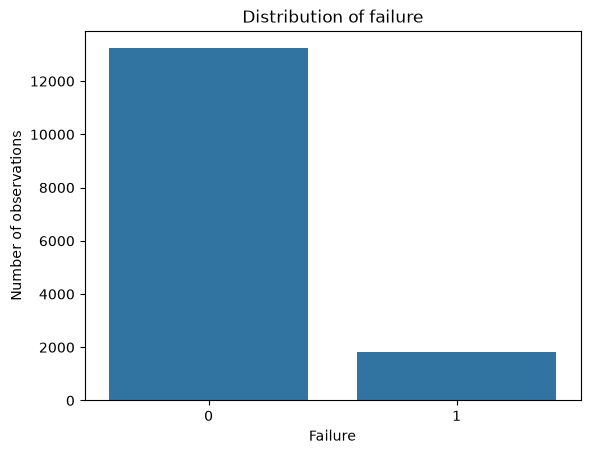

In [11]:
print(readings["failure"].value_counts())
print(readings["failure"].value_counts(normalize=True) * 100)

sns.countplot(
    data=readings,
    x="failure"
)

plt.title("Distribution of failure")
plt.xlabel("Failure")
plt.ylabel("Number of observations")
plt.show()



Zistili sme počet a percentuálny podiel hodnôt cieľovej premennej failure (0 a 1). Pomocou stĺpcového grafu sme vizualizovali ich rozdelenie a overili, či sú triedy v dátach vyvážené.

### 1.1C Párová analýza dát

,currentMotor,dp_filter,temperatureOil,pressure_reservoir,pressure_oil,rms_vibration,Flowmeter,discharge_dewpoint
currentMotor,1.000,0.001,0.001,0.019,0.012,0.006,-0.006,-0.005
dp_filter,0.001,1.000,0.006,-0.001,-0.004,-0.007,-0.006,-0.011
temperatureOil,0.001,0.006,1.000,0.001,0.000,0.006,0.011,-0.002
pressure_reservoir,0.019,-0.001,0.001,1.000,0.852,-0.009,-0.004,-0.003
pressure_oil,0.012,-0.004,0.000,0.852,1.000,-0.002,0.001,-0.010
rms_vibration,0.006,-0.007,0.006,-0.009,-0.002,1.000,-0.011,0.002
Flowmeter,-0.006,-0.006,0.011,-0.004,0.001,-0.011,1.000,-0.004
discharge_dewpoint,-0.005,-0.011,-0.002,-0.003,-0.010,0.002,-0.004,1.000


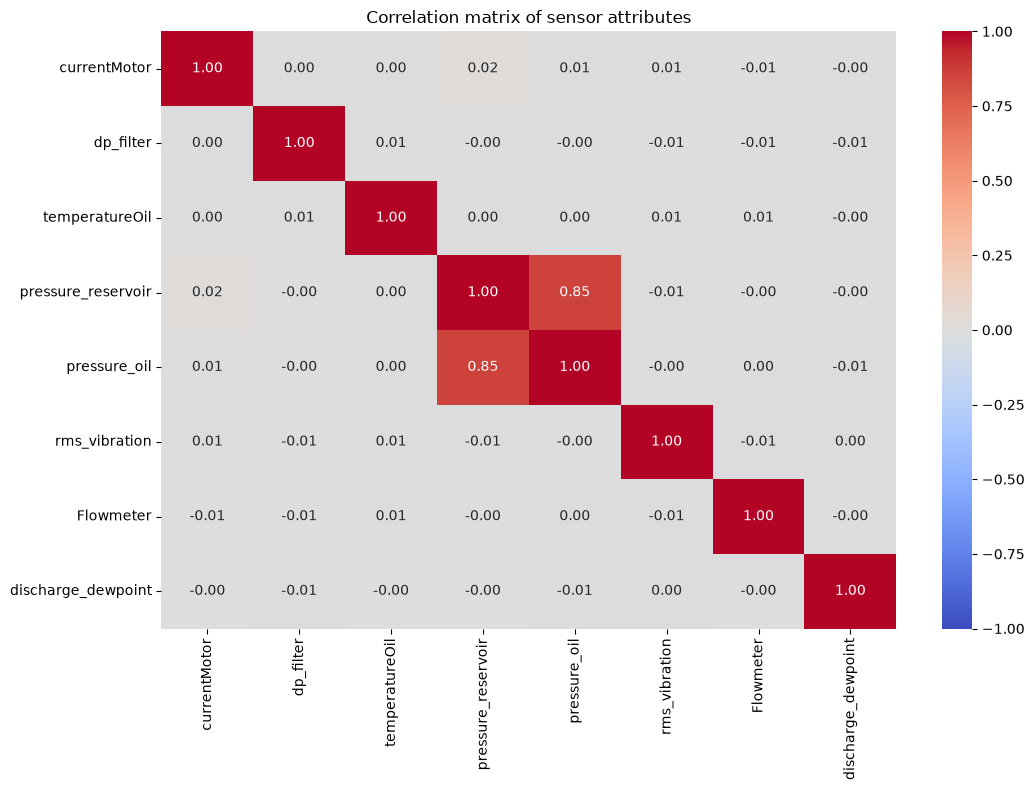

In [12]:
correlation = readings[sensor_attributes].corr()

display(correlation.round(3))

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation matrix of sensor attributes")
plt.tight_layout()
plt.show()

Vypočítali sme korelačnú maticu pre 8 senzorových atribútov a vizualizovali ju pomocou heatmapy. Cieľom bolo identifikovať silné pozitívne a negatívne lineárne závislosti medzi jednotlivými atribútmi.

In [13]:
mask = np.triu(
    np.ones(correlation.shape, dtype=bool),
    k=1
)

pairs = correlation.where(mask).stack()

strongest_pairs = pairs.reindex(
    pairs.abs().sort_values(ascending=False).index
)

display(strongest_pairs.head(10))

pressure_reservoir  pressure_oil          0.852449
currentMotor        pressure_reservoir    0.018768
                    pressure_oil          0.012114
dp_filter           discharge_dewpoint   -0.011412
rms_vibration       Flowmeter            -0.011023
temperatureOil      Flowmeter             0.011018
pressure_oil        discharge_dewpoint   -0.010386
pressure_reservoir  rms_vibration        -0.008787
dp_filter           rms_vibration        -0.007339
                    Flowmeter            -0.006383
dtype: float64

Z korelačnej matice sme vybrali 10 dvojíc atribútov s najvyššou absolútnou hodnotou korelácie. Cieľom bolo identifikovať najsilnejšie pozitívne a negatívne lineárne závislosti medzi senzorovými atribútmi.

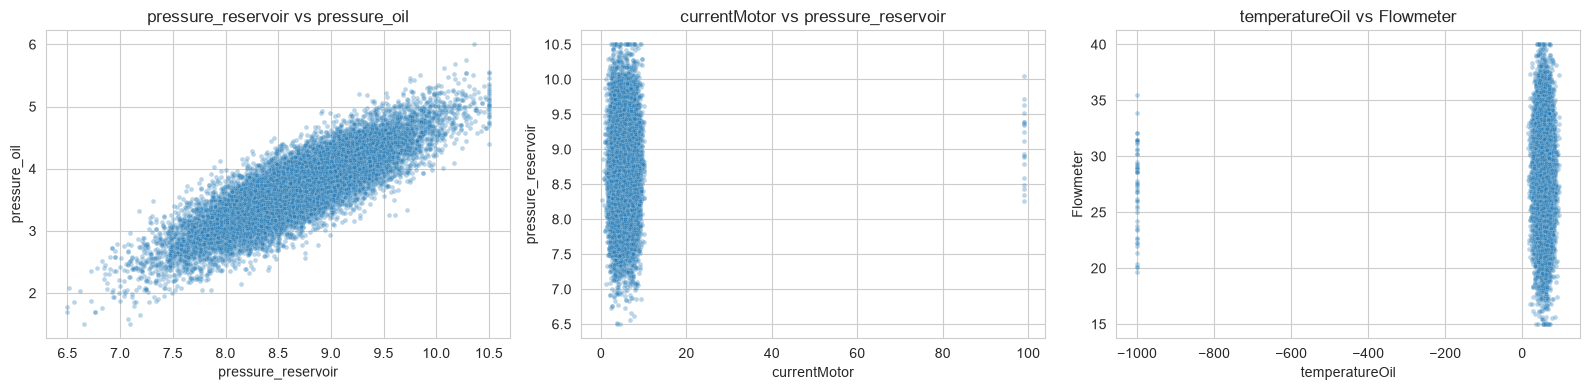

In [40]:
pairs_to_plot = [
    ("pressure_reservoir", "pressure_oil"),
    ("currentMotor", "pressure_reservoir"),
    ("temperatureOil", "Flowmeter")
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (x, y) in zip(axes, pairs_to_plot):
    sns.scatterplot(
        data=readings,
        x=x,
        y=y,
        alpha=0.3,
        s=12,
        ax=ax
    )

    ax.set_title(f"{x} vs {y}")

plt.tight_layout()
plt.show()

Medzi atribútmi pressure_reservoir a pressure_oil sme pozorovali silnú pozitívnu lineárnu závislosť. Pri dvojiciach currentMotor a pressure_reservoir, ako aj temperatureOil a Flowmeter, sme nepozorovali výraznú lineárnu závislosť.

Zároveň sme identifikovali podozrivé extrémne hodnoty, napríklad currentMotor = 99 a temperatureOil = -999.

### D. Závislosti medzi failure a prediktormi

In [15]:
failure_corr = readings[sensor_attributes + ["failure"]].corr()["failure"]

failure_corr = failure_corr.drop("failure")
failure_corr = failure_corr.reindex(
    failure_corr.abs().sort_values(ascending=False).index
)

display(failure_corr.to_frame("Correlation with failure"))
group_stats = readings.groupby("failure")[sensor_attributes].agg(
    ["count", "mean", "median", "std"]
)

,Correlation with failure
dp_filter,0.117892
pressure_reservoir,-0.085653
discharge_dewpoint,0.081442
pressure_oil,-0.077665
rms_vibration,0.059180
Flowmeter,-0.042867
currentMotor,-0.028818
temperatureOil,-0.000780


Vypočítali sme korelácie medzi senzorovými atribútmi a cieľovou premennou failure a zoradili ich podľa absolútnej hodnoty korelácie. Následne sme pre jednotlivé skupiny (`failure = 0` a `failure = 1`) vypočítali počet hodnôt, priemer, medián a štandardnú odchýlku.

In [16]:
display(group_stats.T)

failure                               0            1
currentMotor       count   13227.000000  1814.000000
                   mean        5.372459     5.035851
                   median      5.192680     4.661315
                   std         3.837782     3.535804
dp_filter          count   12977.000000  1476.000000
                   mean       23.614772    27.986748
                   median     21.044820    24.920630
                   std        10.864953    13.415976
temperatureOil     count   13227.000000  1814.000000
                   mean       51.279423    51.127040
                   median     55.056980    54.703045
                   std        63.804282    61.998184
pressure_reservoir count   13227.000000  1814.000000
                   mean        8.718318     8.559547
                   median      8.715380     8.540915
                   std         0.600698     0.607249
pressure_oil       count   13227.000000  1814.000000
                   mean        3.713279     3.577169
                   median      3.722730     3.581065
                   std         0.569419     0.566383
rms_vibration      count   12963.000000  1494.000000
                   mean        3.050546     3.369898
                   median      2.697230     2.931705
                   std         1.612011     1.864349
Flowmeter          count   13227.000000  1814.000000
                   mean       28.109172    27.588152
                   median     28.078220    27.551215
                   std         3.965892     3.873561
discharge_dewpoint count   13227.000000  1814.000000
                   mean        7.929126     8.799864
                   median      7.940570     8.738600
                   std         3.461096     3.538583

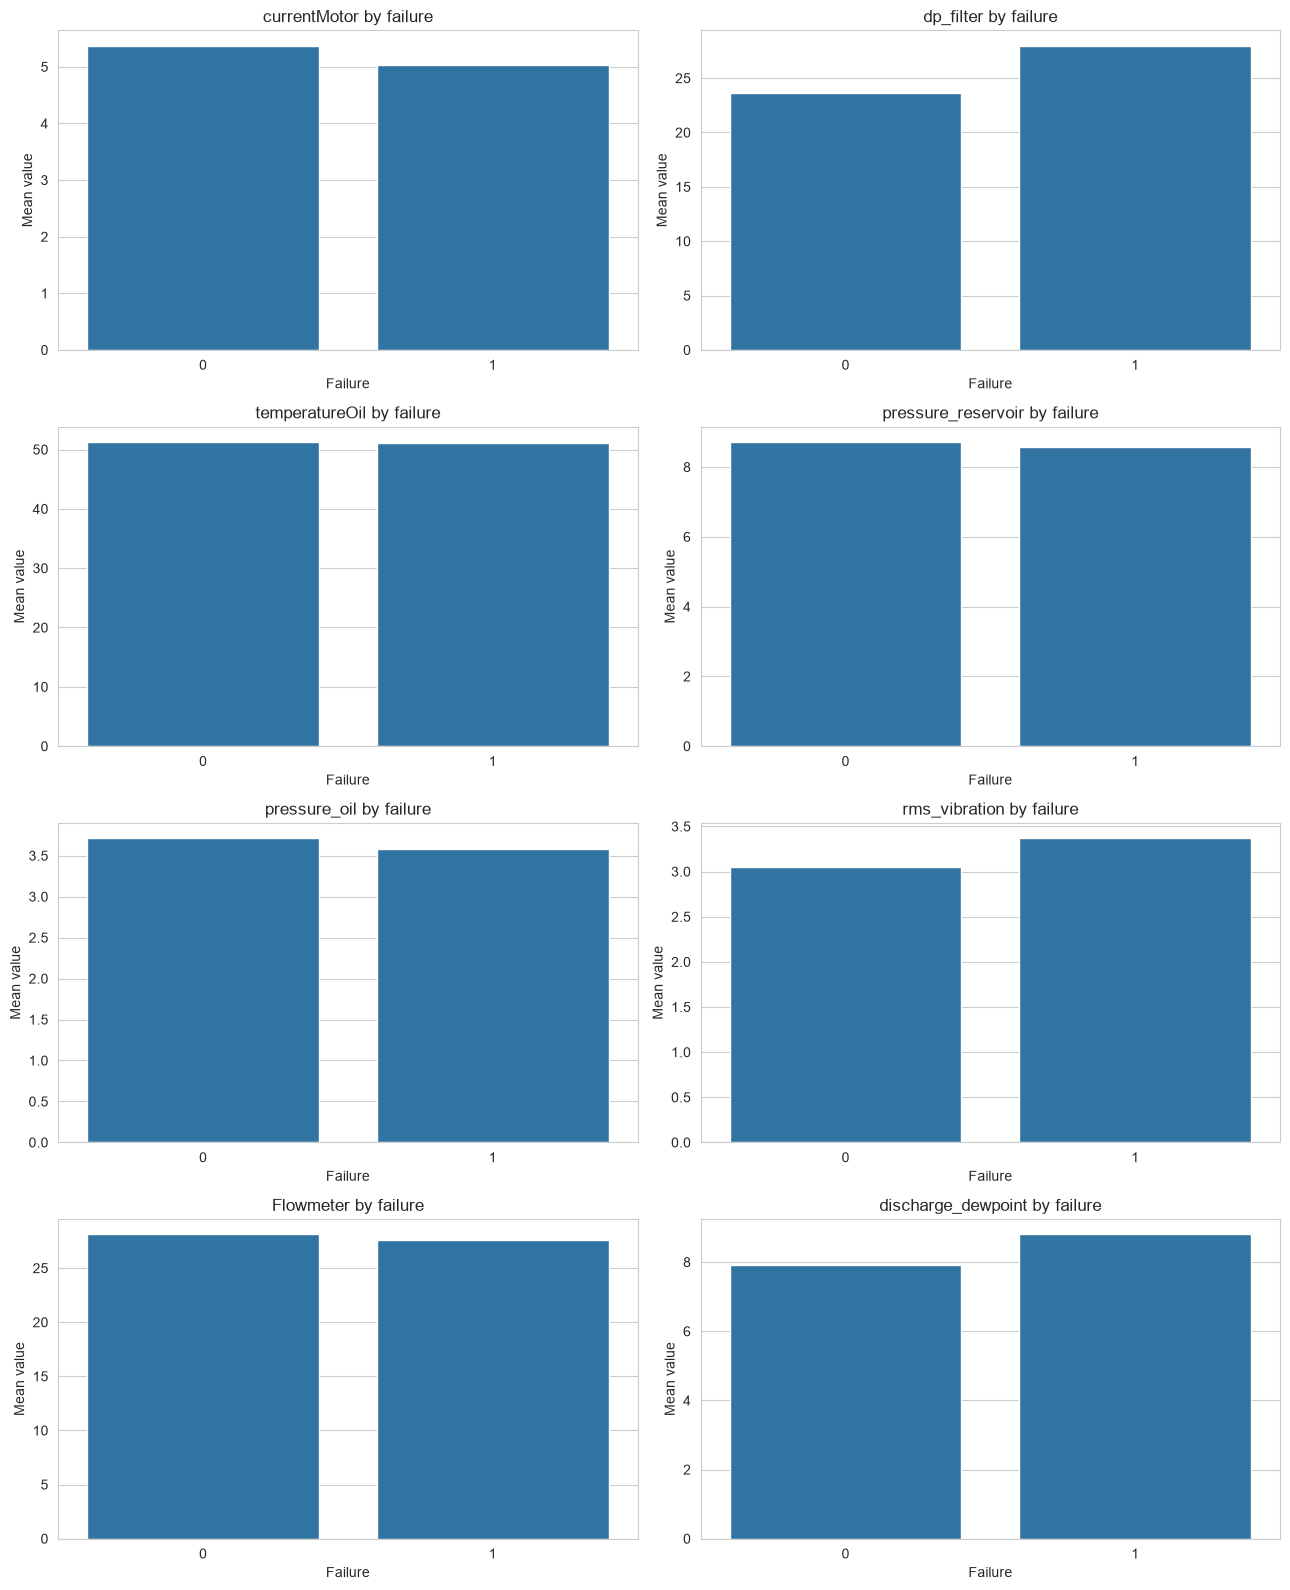

In [24]:
fig, axes = plt.subplots(4, 2, figsize=(13, 16))

for ax, column in zip(axes.flatten(), sensor_attributes):
    sns.barplot(
        data=readings,
        x="failure",
        y=column,
        errorbar=None,
        ax=ax
    )

    ax.set_title(f"{column} by failure")
    ax.set_xlabel("Failure")
    ax.set_ylabel("Mean value")

plt.tight_layout()
plt.show()

Pri porovnaní priemerných hodnôt sme zistili, že atribúty dp_filter, rms_vibration a discharge_dewpoint dosahujú vyššie hodnoty pri failure = 1. Najvýraznejší rozdiel pozorujeme pri atribúte dp_filter. Atribúty currentMotor, pressure_reservoir, pressure_oil a Flowmeter majú pri zlyhaní mierne nižšie priemerné hodnoty.

Pri atribúte temperatureOil sú priemerné hodnoty v oboch skupinách takmer rovnaké.

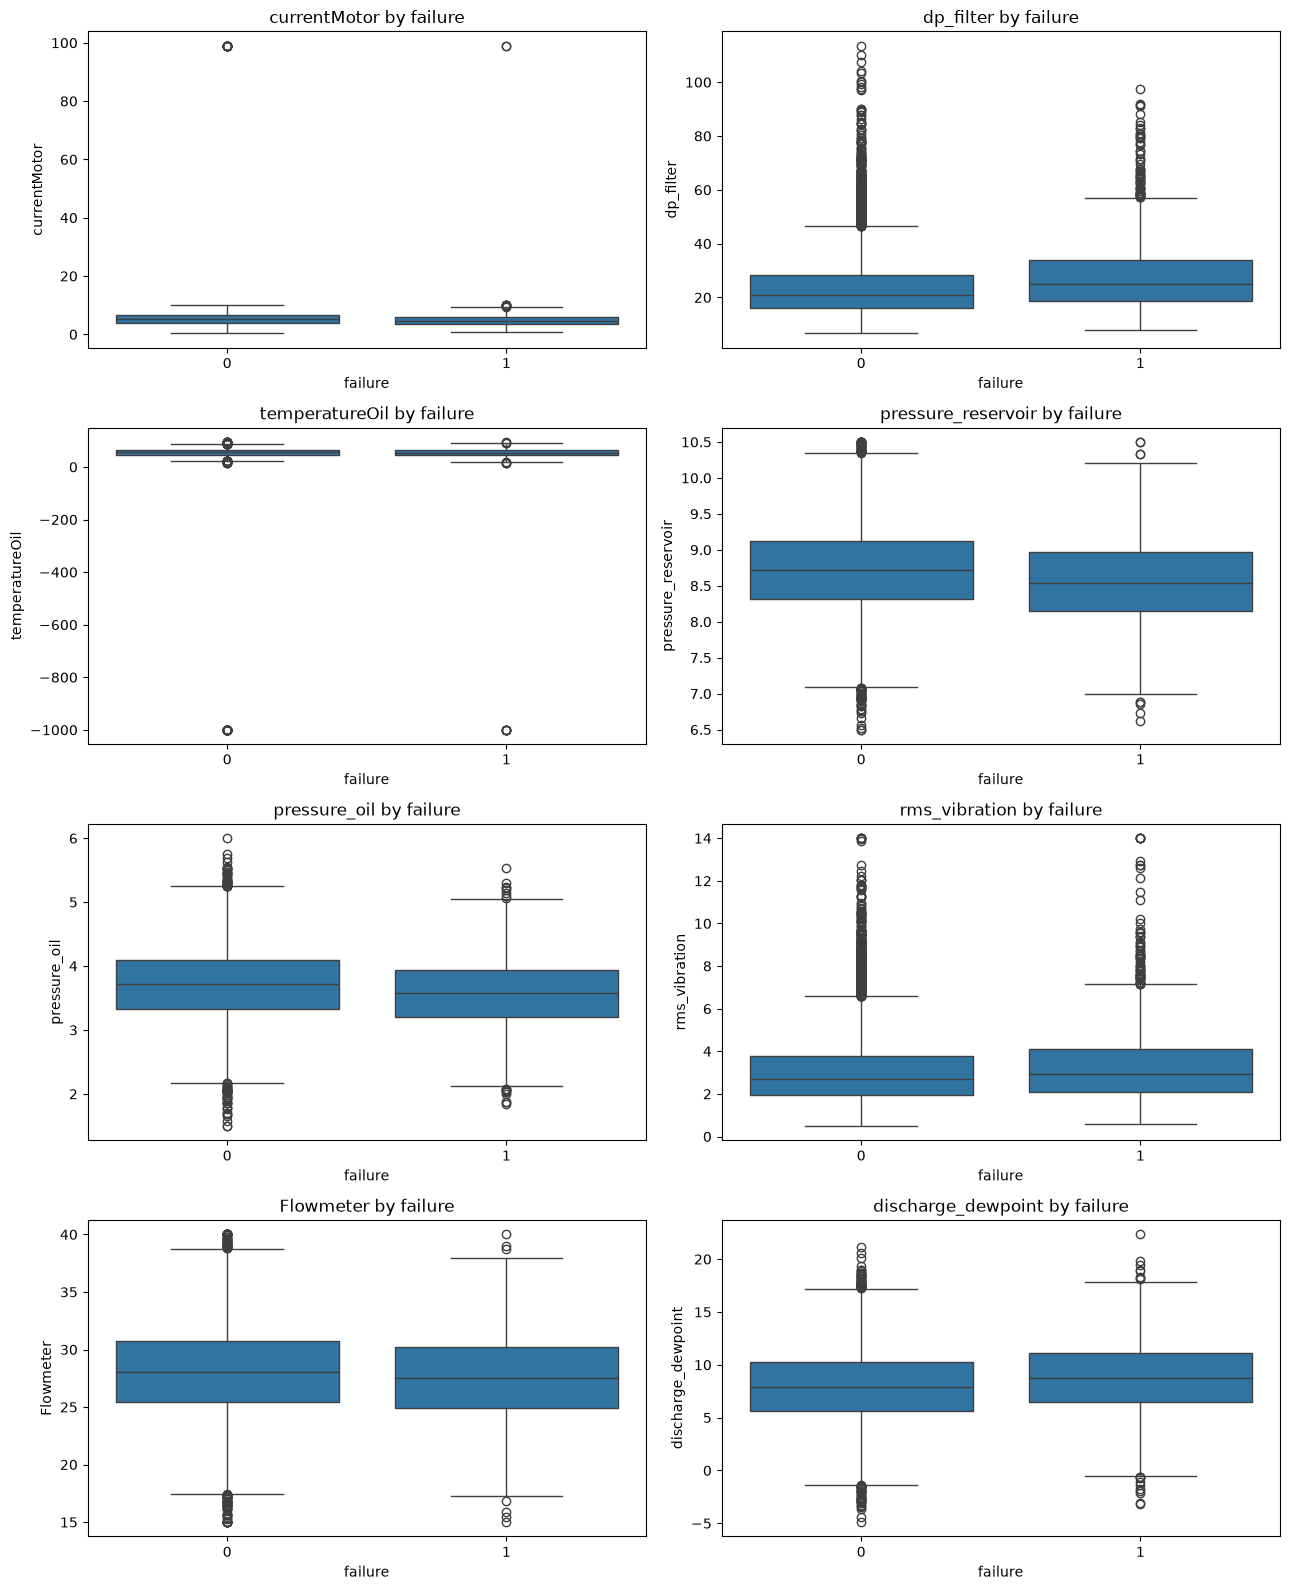

In [18]:
fig, axes = plt.subplots(4, 2, figsize=(13, 16))

for ax, column in zip(axes.flatten(), sensor_attributes):
    sns.boxplot(
        data=readings,
        x="failure",
        y=column,
        ax=ax
    )

    ax.set_title(f"{column} by failure")

plt.tight_layout()
plt.show()

Z boxplotov vidíme, že atribúty dp_filter, rms_vibration a discharge_dewpoint majú pri failure = 1 vyššie mediánové hodnoty ako pri failure = 0. Atribúty pressure_reservoir, pressure_oil a Flowmeter vykazujú pri zlyhaní mierne nižšie mediány. Pri currentMotor sú rozdiely malé. Vo viacerých atribútoch sa nachádzajú odľahlé hodnoty, najmä pri dp_filter a rms_vibration. Pri temperatureOil vidíme extrémne hodnoty okolo -999, ktoré výrazne ovplyvňujú zobrazenie boxplotu a bude potrebné ich riešiť pri čistení dát.

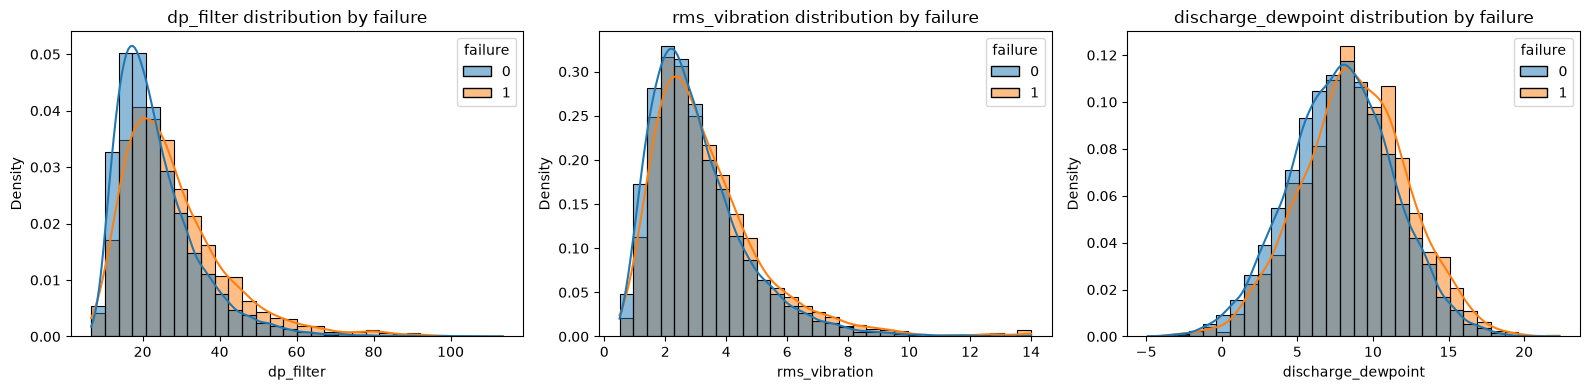

In [19]:
important_attributes = [
    "dp_filter",
    "rms_vibration",
    "discharge_dewpoint"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, column in zip(axes, important_attributes):
    sns.histplot(
        data=readings,
        x=column,
        hue="failure",
        stat="density",
        common_norm=False,
        kde=True,
        bins=30,
        ax=ax
    )

    ax.set_title(f"{column} distribution by failure")

plt.tight_layout()
plt.show()

Pri atribútoch dp_filter, rms_vibration a discharge_dewpoint pozorujeme posun rozdelenia hodnôt smerom k vyšším hodnotám pri failure = 1. Najvýraznejší rozdiel je pri atribúte dp_filter, čo naznačuje jeho potenciálnu súvislosť so zlyhaním zariadenia.

### E. Prvotné zamyslenie nad riešením

Na základe vykonanej analýzy sme zistili, že niektoré atribúty sú medzi sebou závislé. Napríklad `pressure_reservoir` a `pressure_oil` majú silnú pozitívnu koreláciu (približne 0,85).

Pri analýze cieľovej premennej `failure` sme zistili, že najvýraznejšiu závislosť vykazuje atribút `dp_filter`. Vyššie hodnoty pri zlyhaní sme pozorovali aj pri atribútoch `rms_vibration` a `discharge_dewpoint`. Tieto závislosti sú však pomerne slabé.

Pre ďalšie spracovanie bude pravdepodobne vhodné prepojiť súbory `readings.csv` a `units.csv` pomocou atribútu `idUnit`. Takto môžeme doplniť senzorové merania o informácie o zariadeniach.

V ďalších krokoch sa zameriame na čistenie dát a prípravu atribútov pre strojové učenie.

## 1.2 Identifikácia problémov, integrácia a čistenie dát

### A. Identifikácia a riešenie problémov

In [20]:
units_clean = units.copy()
gateways_clean = gateways.copy()
readings_clean = readings.copy()

print("Original datasets:")
for name, df in datasets.items():
    print(f"{name}: {df.shape}")
def missing_values_table(df):
    missing = pd.DataFrame({
        "Missing count": df.isna().sum(),
        "Missing percentage": df.isna().mean() * 100
    })

    return missing[missing["Missing count"] > 0]


Original datasets:
units: (2000, 9)
gateways: (16000, 14)
readings: (15041, 11)


In [21]:
for name, df in datasets.items():
    print(f"\n{name.upper()}")
    display(missing_values_table(df))


UNITS


,Missing count,Missing percentage
serviceHours,100,5.0



GATEWAYS


,Missing count,Missing percentage
idUnit,14000,87.5



READINGS


,Missing count,Missing percentage
dp_filter,588,3.909315
rms_vibration,584,3.882721


In [22]:
for name, df in [
    ("units", units_clean),
    ("gateways", gateways_clean),
    ("readings", readings_clean)
]:
    print(f"{name}: {df.duplicated().sum()} duplicates")

units: 0 duplicates
gateways: 0 duplicates
readings: 222 duplicates


In [23]:
readings_clean = readings_clean.drop_duplicates().copy()

print("\nReadings after removing duplicates:")
print(readings_clean.shape)


Readings after removing duplicates:
(14819, 11)


In [24]:
readings_clean["idUnit"] = pd.to_numeric(
    readings_clean["idUnit"].str.extract(r"^U(\d+)$")[0],
    errors="coerce"
).astype("Int64")

units_clean["idUnit"] = units_clean["idUnit"].astype("Int64")

gateways_clean["idUnit"] = gateways_clean["idUnit"].astype("Int64")

print(readings_clean["idUnit"].head())
print(units_clean["idUnit"].head())

print(readings_clean["idUnit"].isna().sum())

0     861
1     339
2    1862
3     659
4     964
Name: idUnit, dtype: Int64
0    1
1    2
2    3
3    4
4    5
Name: idUnit, dtype: Int64
0


Zjednotili sme formát atribútu idUnit vo všetkých troch dátových súboroch na celočíselný typ Int64. V súbore readings sme odstránili prefix U a identifikátory previedli na čísla. Následne sme zobrazili prvých päť hodnôt a skontrolovali, či pri konverzii nevznikli chýbajúce hodnoty. Táto úprava umožní správne prepojenie dátových súborov pomocou idUnit.

In [25]:
gateways_clean["lastSeen"] = pd.to_datetime(
    gateways_clean["lastSeen"],
    format="mixed",
    errors="coerce"
)

gateways_clean["dateInstall"] = pd.to_datetime(
    gateways_clean["dateInstall"],
    format="mixed",
    errors="coerce"
)

readings_clean["tsCycle"] = pd.to_datetime(
    readings_clean["tsCycle"],
    format="mixed",
    errors="coerce"
)

for name, df, column in [
    ("gateways", gateways_clean, "lastSeen"),
    ("gateways", gateways_clean, "dateInstall"),
    ("readings", readings_clean, "tsCycle")
]:
    print(name, column, "NaT:", df[column].isna().sum())

gateways lastSeen NaT: 0
gateways dateInstall NaT: 0
readings tsCycle NaT: 0


Pomocou funkcie pd.to_datetime() sme skonvertovali atribúty lastSeen, dateInstall a tsCycle na dátumový typ. Parameter format="mixed" umožňuje spracovať rôzne formáty dátumov a errors="coerce" nahrádza neplatné alebo nerozpoznané hodnoty za NaT. Následne sme skontrolovali počet chýbajúcich dátumových hodnôt po konverzii.

In [26]:
print(
    "Before:",
    (readings_clean["temperatureOil"] == -999).sum()
)

readings_clean["temperatureOil"] = (
    readings_clean["temperatureOil"].replace(-999, np.nan)
)

print(
    "After:",
    (readings_clean["temperatureOil"] == -999).sum()
)

print(
    "Missing temperatureOil:",
    readings_clean["temperatureOil"].isna().sum()
)

Before: 49
After: 0
Missing temperatureOil: 49


V atribúte temperatureOil sme identifikovali podozrivé hodnoty -999, ktoré pravdepodobne predstavujú neplatné merania. Tieto hodnoty sme nahradili za NaN, aby neovplyvňovali ďalšiu analýzu dát. Následne sme overili, či boli všetky hodnoty -999 nahradené, a zistili sme celkový počet chýbajúcich hodnôt v tomto atribúte.

In [27]:
reading_missing_cols = [
    "dp_filter",
    "rms_vibration",
    "temperatureOil"
]

for col in reading_missing_cols:
    median_value = readings_clean[col].median()

    readings_clean[col] = readings_clean[col].fillna(
        median_value
    )

    print(f"{col}: filled with median {median_value:.3f}")


median_hours = units_clean["serviceHours"].median()

units_clean["serviceHours"] = (
    units_clean["serviceHours"].fillna(median_hours)
)

print("\nMissing values after filling:")
display(missing_values_table(readings_clean))
display(missing_values_table(units_clean))

dp_filter: filled with median 21.355
rms_vibration: filled with median 2.717
temperatureOil: filled with median 55.075

Missing values after filling:


,Missing count,Missing percentage


,Missing count,Missing percentage


Chýbajúce hodnoty v atribútoch dp_filter, rms_vibration, temperatureOil a serviceHours sme nahradili mediánom. Medián sme zvolili preto, že v našich dátach sa nachádzajú aj odľahlé hodnoty, ktoré môžu výrazne ovplyvniť priemer.  Zároveň sme nechceli odstraňovať celé záznamy kvôli chýbajúcim hodnotám, aby sme nestratili informácie, ktoré môžu byť užitočné pri predikcii failure. Nakoniec sme skontrolovali, či sa nám podarilo chýbajúce hodnoty doplniť.

In [28]:
print("Before cleaning:")
print(units_clean["dutyClass"].value_counts())

Before cleaning:
dutyClass
1           251
light       249
L           229
heavy       173
N           159
H           157
2           152
med         149
normal      141
3           133
 1           30
 light       29
 N           27
 heavy       23
 L           22
 3           20
 normal      17
 H           15
 med         15
 2            9
Name: count, dtype: int64


In [41]:
units_clean["dutyClass"] = (
    units_clean["dutyClass"]
    .str.strip()
    .str.lower()
)

print("\nAfter cleaning:")
print(units_clean["dutyClass"].value_counts())


After cleaning:
dutyClass
1         281
light     278
l         251
heavy     196
n         186
h         172
med       164
2         161
normal    158
3         153
Name: count, dtype: int64


V atribúte dutyClass sme zjednotili formát textových hodnôt pomocou metód strip() a lower(). Odstránili sme nadbytočné medzery na začiatku a na konci hodnôt a všetky písmená sme previedli na malé. Porovnali sme počet jednotlivých hodnôt pred úpravou a po nej.

In [42]:
merged_data = readings_clean.merge(
    units_clean,
    on="idUnit",
    how="left",
    validate="many_to_one",
    indicator=True,
    suffixes=("", "_unit")
)

print("Readings:", len(readings_clean))
print("Merged:", len(merged_data))

print("\nMerge results:")
display(merged_data["_merge"].value_counts())

merged_data = merged_data.drop(columns=["_merge"])

Readings: 14819
Merged: 14819

Merge results:


_merge
both          14679
left_only       140
right_only        0
Name: count, dtype: int64

In [30]:
display(merged_data.head())

,idUnit,tsCycle,currentMotor,dp_filter,temperatureOil,pressure_reservoir,pressure_oil,rms_vibration,Flowmeter,discharge_dewpoint,failure,year_commission,operatorOwner,number_serial,idDepot,codeLine,serviceHours,code_model,dutyClass
0,861,2023-01-24 00:00:00,4.52714,13.27287,38.37190,8.71234,3.20650,2.98947,26.46027,9.88857,0,2021.0,Smith Inc,YF-9652-68924,33.0,L6,11660.4,APU-15,l
1,339,2023-03-23 00:00:00,4.29990,30.68875,62.89222,8.30207,3.50414,5.42665,30.37617,3.50537,0,2021.0,Speer Aumann GmbH & Co. KG,DV-8136-59323,2.0,L5,13438.9,XC-7,light
2,1862,2023-01-02 00:00:00,2.67461,20.64984,44.05538,8.53038,3.31134,3.19845,15.69089,0.94667,0,2023.0,Smith Inc,RZ-8097-07999,67.0,L3,6663.4,APU-20,1
3,659,2023-11-27 00:00:00,4.06722,30.65835,76.27459,8.98351,3.88235,2.13170,24.62591,12.19307,1,2017.0,Killer Ladeck GmbH & Co. KG,FB-1611-52787,12.0,L4,24578.2,APU-15,1
4,964,2023-12-30 22:08:00,7.30514,23.53441,57.95202,8.31182,3.18153,2.50357,21.52352,11.89736,0,2017.0,"Bryant, Williams and Roberts",RJ-8551-19225,29.0,L1,26640.5,APU-20,h


Súbory readings_clean a units_clean sme spojili pomocou atribútu idUnit, pretože obsahujú rôzne informácie o rovnakých zariadeniach. Súbor readings_clean obsahuje senzorové merania a cieľovú premennú failure, zatiaľ čo units_clean obsahuje ďalšie informácie o zariadeniach, napríklad model, počet prevádzkových hodín a rok uvedenia do prevádzky. Spojením týchto súborov získame viac atribútov, ktoré môžu byť užitočné pri predikcii zlyhania. Použili sme left join, aby sme zachovali všetky senzorové merania, aj keď k niektorým zariadeniam nemáme doplňujúce informácie. Pomocou validate="many_to_one" sme overili správnosť vzťahu medzi tabuľkami a následne skontrolovali počet záznamov pred spojením a po ňom.

### B. Kontrola správnosti dát

In [43]:
sensor_check_before = pd.DataFrame({
    "Min": readings[sensor_attributes].min(),
    "Max": readings[sensor_attributes].max(),
    "Zero values": (readings[sensor_attributes] == 0).sum(),
    "Negative values": (readings[sensor_attributes] < 0).sum(),
    "Missing values": readings[sensor_attributes].isna().sum()
})

sensor_check_after = pd.DataFrame({
    "Min": readings_clean[sensor_attributes].min(),
    "Max": readings_clean[sensor_attributes].max(),
    "Zero values": (readings_clean[sensor_attributes] == 0).sum(),
    "Negative values": (readings_clean[sensor_attributes] < 0).sum(),
    "Missing values": readings_clean[sensor_attributes].isna().sum()
})

print("Before cleaning:")
display(sensor_check_before)

Before cleaning:


,Min,Max,Zero values,Negative values,Missing values
currentMotor,0.33561,99.00000,0,0,0
dp_filter,6.64914,113.55145,0,0,588
temperatureOil,-999.00000,95.00000,0,53,0
pressure_reservoir,6.50000,10.50000,0,0,0
pressure_oil,1.50000,6.00000,0,0,0
rms_vibration,0.50000,14.00000,0,0,584
Flowmeter,15.00000,40.00000,0,0,0
discharge_dewpoint,-4.88825,22.33572,0,160,0


In [44]:
print("After cleaning:")
display(sensor_check_after)

After cleaning:


,Min,Max,Zero values,Negative values,Missing values
currentMotor,0.33561,99.00000,0,0,0
dp_filter,6.64914,113.55145,0,0,0
temperatureOil,15.00000,95.00000,0,0,0
pressure_reservoir,6.50000,10.50000,0,0,0
pressure_oil,1.50000,6.00000,0,0,0
rms_vibration,0.50000,14.00000,0,0,0
Flowmeter,15.00000,40.00000,0,0,0
discharge_dewpoint,-4.88825,22.33572,0,156,0


In [46]:
invalid_dates = (
    gateways_clean["lastSeen"] <
    gateways_clean["dateInstall"]
)

print("Gateways with lastSeen before dateInstall:")
print(invalid_dates.sum())

display(
    gateways_clean.loc[
        invalid_dates,
        ["id_gateway", "dateInstall", "lastSeen"]
    ].head(10)
)

duplicate_measurements = readings_clean.duplicated(
    subset=["idUnit", "tsCycle"],
    keep=False
)

print("Rows sharing unit and timestamp:")
print(duplicate_measurements.sum())

Gateways with lastSeen before dateInstall:
721


,id_gateway,dateInstall,lastSeen
7,GW-00007,2024-09-03,2024-07-16
11,GW-00011,2024-11-13,2024-06-08
41,GW-00041,2024-08-03,2024-04-30
67,GW-00067,2024-11-11,2024-03-26
83,GW-00083,2024-04-10,2024-01-23
115,GW-00115,2024-06-02,2024-02-16
117,GW-00117,2024-11-23,2024-09-30
132,GW-00132,2024-07-24,2024-05-15
133,GW-00133,2024-10-14,2024-10-11
137,GW-00137,2024-08-22,2024-01-04


Rows sharing unit and timestamp:
161


In [47]:
display(
    readings_clean.loc[duplicate_measurements]
    .sort_values(["idUnit", "tsCycle"])
    .head(20)
)

print("Failure values:")
print(readings_clean["failure"].value_counts(dropna=False))

invalid_failure = ~readings_clean["failure"].isin([0, 1])

print("Invalid failure values:", invalid_failure.sum())

,idUnit,tsCycle,currentMotor,dp_filter,temperatureOil,pressure_reservoir,pressure_oil,rms_vibration,Flowmeter,discharge_dewpoint,failure
2674,24,2023-05-01,3.26378,18.28350,68.87724,9.10262,4.23268,3.492480,31.87744,12.18193,0
6143,24,2023-05-01,3.35807,22.13903,53.11614,9.33545,4.19346,2.116730,22.74323,5.03497,0
5752,33,2023-06-24,4.82756,17.56122,46.09724,9.41263,4.21727,1.695950,28.26960,8.17711,0
13271,33,2023-06-24,6.58982,17.34402,70.90096,8.05656,3.04276,2.229760,15.00000,7.88986,0
5749,37,2023-11-26,4.74459,23.16488,68.89369,8.00559,3.98054,3.087230,21.97706,11.72689,0
9985,37,2023-11-26,4.00420,13.40114,70.37491,8.11847,3.87498,1.796610,25.94196,6.42388,0
945,38,2023-03-15,3.87714,41.39966,46.83104,7.90196,2.55956,2.018990,25.90530,11.00236,0
14239,38,2023-03-15,4.32318,19.19209,64.09954,8.94048,3.54762,2.716745,30.03639,9.30244,0
6647,42,2023-09-06,5.38121,14.09272,58.88258,9.05072,4.10280,2.114160,25.26607,9.84881,0
9495,42,2023-09-06,5.16616,21.94164,57.64266,9.21467,3.79342,8.791570,23.60840,2.71920,0


Failure values:
failure
0    13026
1     1793
Name: count, dtype: int64
Invalid failure values: 0


Aby sme identifikovali možné nekonzistentné a duplicitné záznamy, rozhodli sme sa vykonať ďalšie kontroly. Najprv sme overili, či dátum poslednej komunikácie (`lastSeen`) nie je skorší ako dátum inštalácie (`dateInstall`), pretože je to nelogicke. Následne sme skontrolovali, či sa v dátach nenachádzajú viaceré merania pre rovnaké zariadenie (`idUnit`) v rovnakom čase (`tsCycle`).

### C. Detekcia a riešenie odľahlých hodnôt

In [48]:
q1 = readings_clean[sensor_attributes].quantile(0.25)
q3 = readings_clean[sensor_attributes].quantile(0.75)
iqr = q3 - q1

lower_bounds = q1 - 1.5 * iqr
upper_bounds = q3 + 1.5 * iqr

outlier_mask = (
    (readings_clean[sensor_attributes] < lower_bounds) |
    (readings_clean[sensor_attributes] > upper_bounds)
)

outlier_summary = pd.DataFrame({
    "Lower bound": lower_bounds,
    "Upper bound": upper_bounds,
    "Outlier count": outlier_mask.sum(),
    "Outlier percentage (%)": (
        outlier_mask.sum() / len(readings_clean) * 100
    ).round(2)
})

display(outlier_summary.sort_values(
    "Outlier percentage (%)", ascending=False
))


,Lower bound,Upper bound,Outlier count,Outlier percentage (%)
dp_filter,-1.430367,46.351052,670,4.52
rms_vibration,-0.712713,6.457388,615,4.15
Flowmeter,17.324223,38.759682,104,0.70
discharge_dewpoint,-1.366857,17.411282,99,0.67
pressure_reservoir,7.061485,10.335605,96,0.65
pressure_oil,2.145498,5.239158,90,0.61
temperatureOil,22.194112,87.796572,89,0.60
currentMotor,-0.651238,11.055943,19,0.13


In [49]:
rows_with_outliers = outlier_mask.any(axis=1)

readings_iqr = readings_clean.loc[
    ~rows_with_outliers
].copy()

print("Original number of observations:", len(readings_clean))
print("Observations with outliers:", rows_with_outliers.sum())
print("Observations removed:", len(readings_clean) - len(readings_iqr))
print("Remaining observations:", len(readings_iqr))

print("\nFailure distribution before removal (%):")
display(
    (readings_clean["failure"].value_counts(normalize=True) * 100)
    .sort_index().rename("Percentage")
)

print("\nFailure distribution after removal (%):")
display(
    (readings_iqr["failure"].value_counts(normalize=True) * 100)
    .sort_index().rename("Percentage")
)


Original number of observations: 14819
Observations with outliers: 1690
Observations removed: 1690
Remaining observations: 13129

Failure distribution before removal (%):


failure
0    87.900668
1    12.099332
Name: Percentage, dtype: float64


Failure distribution after removal (%):


failure
0    88.521593
1    11.478407
Name: Percentage, dtype: float64

Prvá metóda – IQR. Odľahlé hodnoty sme identifikovali pomocou medzikvartilového rozpätia (IQR). Za odľahlé sme považovali hodnoty menšie ako

$$
Q_1 - 1.5 \cdot IQR
$$

alebo väčšie ako

$$
Q_3 + 1.5 \cdot IQR
$$

Následne sme vytvorili samostatnú dátovú množinu bez pozorovaní, ktoré obsahovali aspoň jednu odľahlú hodnotu vo vybraných senzorových atribútoch.

In [50]:
lower_percentiles = readings_clean[sensor_attributes].quantile(0.05)
upper_percentiles = readings_clean[sensor_attributes].quantile(0.95)

readings_winsorized = readings_clean.copy()

readings_winsorized[sensor_attributes] = (
    readings_winsorized[sensor_attributes]
    .clip(
        lower=lower_percentiles,
        upper=upper_percentiles,
        axis="columns"
    )
)

winsorization_summary = pd.DataFrame({
    "5th percentile": lower_percentiles,
    "95th percentile": upper_percentiles,
    "Values changed": (
        (readings_clean[sensor_attributes] <
         lower_percentiles) |
        (readings_clean[sensor_attributes] >
         upper_percentiles)
    ).sum(),
    "Original minimum": readings_clean[sensor_attributes].min(),
    "New minimum": readings_winsorized[sensor_attributes].min(),
    "Original maximum": readings_clean[sensor_attributes].max(),
    "New maximum": readings_winsorized[sensor_attributes].max()
})

display(winsorization_summary)

,5th percentile,95th percentile,Values changed,Original minimum,New minimum,Original maximum,New maximum
currentMotor,2.458449,8.301255,1482,0.33561,2.458449,99.00000,8.301255
dp_filter,11.639794,45.166674,1482,6.64914,11.639794,113.55145,45.166674
temperatureOil,35.169778,74.551229,1482,15.00000,35.169778,95.00000,74.551229
pressure_reservoir,7.706360,9.699153,1482,6.50000,7.706360,10.50000,9.699153
pressure_oil,2.756013,4.624229,1482,1.50000,2.756013,6.00000,4.624229
rms_vibration,1.182389,6.180937,1482,0.50000,1.182389,14.00000,6.180937
Flowmeter,21.469522,34.480967,1482,15.00000,21.469522,40.00000,34.480967
discharge_dewpoint,2.296975,13.760702,1482,-4.88825,2.296975,22.33572,13.760702


Druhá metóda – Winsorizácia. Pri druhej metóde sme hodnoty senzorových atribútov obmedzili na interval medzi 5. a 95. percentilom. Na rozdiel od prvej metódy sa počet pozorovaní nezmenil, upravili sa iba extrémne hodnoty.

In [52]:
comparison = pd.DataFrame({
    "Original": readings_clean[sensor_attributes].count(),
    "IQR removal": readings_iqr[sensor_attributes].count(),
    "Winsorization": readings_winsorized[sensor_attributes].count()
})

display(comparison)

,Original,IQR removal,Winsorization
currentMotor,14819,13129,14819
dp_filter,14819,13129,14819
temperatureOil,14819,13129,14819
pressure_reservoir,14819,13129,14819
pressure_oil,14819,13129,14819
rms_vibration,14819,13129,14819
Flowmeter,14819,13129,14819
discharge_dewpoint,14819,13129,14819


Výsledky oboch metód porovnáme z hľadiska počtu odstránených pozorovaní, rozsahu upravených hodnôt, chýbajúcich údajov a zachovania zastúpenia tried cieľovej premennej failure. Pri výbere vhodnej metódy je potrebné zohľadniť, že extrémne hodnoty môžu predstavovať skutočné prejavy poruchy, a nie iba chyby merania.

### Hypotéza 1 – Atribút dp_filter

Atribút dp_filter sme vybrali na základe výsledkov prieskumnej analýzy, pretože vykazoval najvyššiu koreláciu s premennou failure (približne 0,118). Na stĺpcovom grafe sme videli, že priemerná hodnota dp_filter je pri failure = 1 vyššia (27,99) ako pri failure = 0 (23,61). Aj na boxplote sme pozorovali vyšší medián pri zlyhaní a histogramy ukázali posun rozdelenia smerom k vyšším hodnotám, hoci sa obe skupiny prekrývajú.

- Nulová hypotéza (H₀): Priemerná hodnota atribútu dp_filter pri failure = 1 nie je vyššia ako pri failure = 0.
- Alternatívna hypotéza (H₁): Priemerná hodnota atribútu dp_filter pri failure = 1 je vyššia ako pri failure = 0.

Hypotézu overíme jednostranným Welchovým t-testom na hladine významnosti $\alpha = 0{,}05$.

In [58]:
from scipy import stats
from statsmodels.stats.power import TTestIndPower

alpha = 0.05
col = "dp_filter"

group0 = readings_clean.loc[
    readings_clean["failure"] == 0, col
].dropna()

group1 = readings_clean.loc[
    readings_clean["failure"] == 1, col
].dropna()

display(pd.DataFrame({
    "failure = 0": group0.describe(),
    "failure = 1": group1.describe()
}).round(4))

test = stats.ttest_ind(
    group1, group0,
    equal_var=False,
    alternative="greater"
)

pooled_std = np.sqrt(
    ((len(group0) - 1) * group0.var(ddof=1)
     + (len(group1) - 1) * group1.var(ddof=1))
    / (len(group0) + len(group1) - 2)
)

d = (group1.mean() - group0.mean()) / pooled_std

power = TTestIndPower().power(
    effect_size=abs(d),
    nobs1=len(group0),
    ratio=len(group1) / len(group0),
    alpha=alpha,
    alternative="two-sided"
)

print("Hypothesis 1: dp_filter")
print(f"Mean (failure=0): {group0.mean():.4f}")
print(f"Mean (failure=1): {group1.mean():.4f}")
print(f"Mean difference: {group1.mean() - group0.mean():.4f}")
print(f"Welch t-statistic: {test.statistic:.4f}")
print(f"One-sided p-value: {test.pvalue:.6g}")
print(f"Cohen's d: {d:.4f}")
print(f"Approximate achieved power: {power:.4f}")

if test.pvalue < alpha:
    print("Decision: Reject H0. Evidence supports H1.")
else:
    print("Decision: Fail to reject H0. Evidence is insufficient to support H1.")


,failure = 0,failure = 1
count,13026.0000,1793.0000
mean,23.5790,26.7335
std,10.7901,12.3376
min,6.6491,7.9164
25%,16.1820,20.0670
50%,21.2355,21.8141
75%,28.1142,31.3384
max,113.5514,97.3644


Hypothesis 1: dp_filter
Mean (failure=0): 23.5790
Mean (failure=1): 26.7335
Mean difference: 3.1545
Welch t-statistic: 10.2981
One-sided p-value: 1.2788e-24
Cohen's d: 0.2871
Approximate achieved power: 1.0000
Decision: Reject H0. Evidence supports H1.


Na základe výsledkov Welchovho t-testu sme zamietli nulovú hypotézu, pretože p-hodnota (1,28 × 10⁻²⁴) je menšia ako hladina významnosti 0,05. Priemerná hodnota dp_filter je pri failure = 1 vyššia o 3,15. Cohenovo d = 0,2871 naznačuje malý efekt. Výsledky teda podporujú našu alternatívnu hypotézu, že dp_filter má pri zlyhaní vyššiu priemernú hodnotu.

### Hypotéza 2 – Atribút rms_vibration

Atribút rms_vibration sme vybrali na základe výsledkov prieskumnej analýzy, pretože sme pozorovali rozdiely medzi skupinami failure = 0 a failure = 1. Na stĺpcovom grafe sme videli, že priemerná hodnota rms_vibration je pri failure = 1 vyššia (3,37) ako pri failure = 0 (3,05). Aj na boxplote sme pozorovali vyšší medián pri zlyhaní a histogramy ukázali posun rozdelenia smerom k vyšším hodnotám, hoci sa obe skupiny výrazne prekrývajú. Keďže vyššie vibrácie môžu súvisieť s poruchou zariadenia, rozhodli sme sa štatisticky overiť, či je priemerná hodnota rms_vibration pri zlyhaní skutočne vyššia.

- Nulová hypotéza (H₀): Priemerná hodnota atribútu rms_vibration pri failure = 1 nie je vyššia ako pri failure = 0.
- Alternatívna hypotéza (H₁): Priemerná hodnota atribútu rms_vibration pri failure = 1 je vyššia ako pri failure = 0.

Hypotézu overíme jednostranným Welchovým t-testom na hladine významnosti $\alpha = 0{,}05$.

In [60]:
alpha = 0.05
col = "rms_vibration"

group0 = readings_clean.loc[
    readings_clean["failure"] == 0, col
].dropna()

group1 = readings_clean.loc[
    readings_clean["failure"] == 1, col
].dropna()

display(pd.DataFrame({
    "failure = 0": group0.describe(),
    "failure = 1": group1.describe()
}).round(4))

test = stats.ttest_ind(
    group1, group0,
    equal_var=False,
    alternative="greater"
)

pooled_std = np.sqrt(
    ((len(group0) - 1) * group0.var(ddof=1)
     + (len(group1) - 1) * group1.var(ddof=1))
    / (len(group0) + len(group1) - 2)
)

d = (group1.mean() - group0.mean()) / pooled_std

power = TTestIndPower().power(
    effect_size=abs(d),
    nobs1=len(group0),
    ratio=len(group1) / len(group0),
    alpha=alpha,
    alternative="two-sided"
)

print("Hypothesis 2: rms_vibration")
print(f"Mean (failure=0): {group0.mean():.4f}")
print(f"Mean (failure=1): {group1.mean():.4f}")
print(f"Mean difference: {group1.mean() - group0.mean():.4f}")
print(f"Welch t-statistic: {test.statistic:.4f}")
print(f"One-sided p-value: {test.pvalue:.6g}")
print(f"Cohen's d: {d:.4f}")
print(f"Approximate achieved power: {power:.4f}")

if test.pvalue < alpha:
    print("Decision: Reject H0. Evidence supports H1.")
else:
    print("Decision: Fail to reject H0. Evidence is insufficient to support H1.")


,failure = 0,failure = 1
count,13026.0000,1793.0000
mean,3.0446,3.2546
std,1.5989,1.7110
min,0.5000,0.5820
25%,1.9462,2.2781
50%,2.7167,2.7167
75%,3.7584,3.8497
max,14.0000,14.0000


Hypothesis 2: rms_vibration
Mean (failure=0): 3.0446
Mean (failure=1): 3.2546
Mean difference: 0.2101
Welch t-statistic: 4.9119
One-sided p-value: 4.83464e-07
Cohen's d: 0.1302
Approximate achieved power: 0.9993
Decision: Reject H0. Evidence supports H1.


Aj pri atribúte rms_vibration sme zamietli nulovú hypotézu, pretože p-hodnota (4,83 × 10⁻⁷) je menšia ako 0,05. Priemerná hodnota pri failure = 1 je vyššia o 0,21. Cohenovo d = 0,1302 však ukazuje veľmi malý efekt. Rozdiel je teda štatisticky významný, ale v praxi pomerne malý.